In [1]:

!pip install -q tensorflow tensorflow-hub opencv-python matplotlib numpy

In [2]:

import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


All libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

image_path = next(iter(uploaded.keys()))

print("Image uploaded successfully:", image_path)

Saving file_000000008ad8624387027a7203fc6f03_conversation_id=67fce8c8-c710-800d-9c07-611142e4ec33&message_id=ae53d91b-b7f7-4480-9cf4-6870618d144f.webp to file_000000008ad8624387027a7203fc6f03_conversation_id=67fce8c8-c710-800d-9c07-611142e4ec33&message_id=ae53d91b-b7f7-4480-9cf4-6870618d144f (2).webp
Image uploaded successfully: file_000000008ad8624387027a7203fc6f03_conversation_id=67fce8c8-c710-800d-9c07-611142e4ec33&message_id=ae53d91b-b7f7-4480-9cf4-6870618d144f (2).webp


In [4]:

model_url = "https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1"

model = hub.load(model_url)
detector = model.signatures["default"]

print("Object detection model loaded successfully!")


Object detection model loaded successfully!


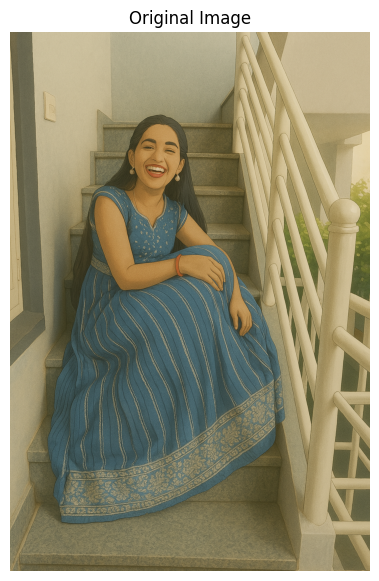

Image dimensions: 1024 x 1536


In [5]:

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image dimensions:", img_rgb.shape[1], "x", img_rgb.shape[0])

In [6]:

# Convert image to a TensorFlow tensor with float32 data type
image_tensor = tf.convert_to_tensor(
    img_rgb, dtype=tf.float32
)

# Add batch dimension
image_tensor = image_tensor[tf.newaxis, ...]

print("Image tensor shape:", image_tensor.shape)
print("Image tensor data type:", image_tensor.dtype)

# Run object detection
results = detector(image_tensor)

# Convert results to NumPy arrays
results = {
    key: value.numpy()
    for key, value in results.items()
}

print("Object detection completed successfully!")
print("Available outputs:", list(results.keys()))

Image tensor shape: (1, 1536, 1024, 3)
Image tensor data type: <dtype: 'float32'>
Object detection completed successfully!
Available outputs: ['detection_scores', 'detection_class_entities', 'detection_class_labels', 'detection_class_names', 'detection_boxes']


In [7]:

scores = np.asarray(results["detection_scores"]).reshape(-1)
classes = np.asarray(results["detection_class_entities"]).reshape(-1)

print("Top 10 predictions:")

for i in np.argsort(scores)[::-1][:10]:
    label = classes[i]

    if isinstance(label, bytes):
        label = label.decode("utf-8")

    print(label, ":", round(float(scores[i]) * 100, 2), "%")

Top 10 predictions:
Person : 33.57 %
Clothing : 26.83 %
Human face : 12.88 %
Car : 12.65 %
Human face : 9.99 %
Clothing : 9.15 %
Man : 8.33 %
Car : 7.79 %
Human face : 7.61 %
Clothing : 7.33 %


In [10]:

print("Human-related predictions:")

for i, raw_label in enumerate(classes):
    label = (
        raw_label.decode("utf-8")
        if isinstance(raw_label, bytes)
        else str(raw_label)
    )

    if any(word in label.lower()
           for word in ["person", "human", "face", "man", "woman"]):
        print(label, ":", round(float(scores[i]) * 100, 2), "%")


Human-related predictions:
Person : 33.57 %
Human face : 12.88 %
Human face : 9.99 %
Man : 8.33 %
Human face : 7.61 %
Human face : 6.91 %
Human face : 6.55 %
Human face : 5.63 %
Human face : 5.52 %
Human face : 5.51 %
Person : 5.31 %
Human face : 5.31 %
Human face : 5.03 %
Human face : 4.84 %
Human face : 4.7 %
Human face : 4.66 %
Human face : 4.61 %
Human face : 4.45 %
Human face : 4.38 %
Human face : 4.11 %
Human face : 3.89 %
Human face : 3.84 %
Human face : 3.83 %
Person : 3.8 %
Person : 3.59 %
Human face : 3.48 %
Human face : 3.37 %
Human face : 3.34 %
Person : 3.24 %
Human face : 3.2 %
Human face : 3.14 %
Human nose : 3.14 %
Human face : 3.14 %
Human face : 3.13 %
Person : 3.11 %


Person: 33.6%


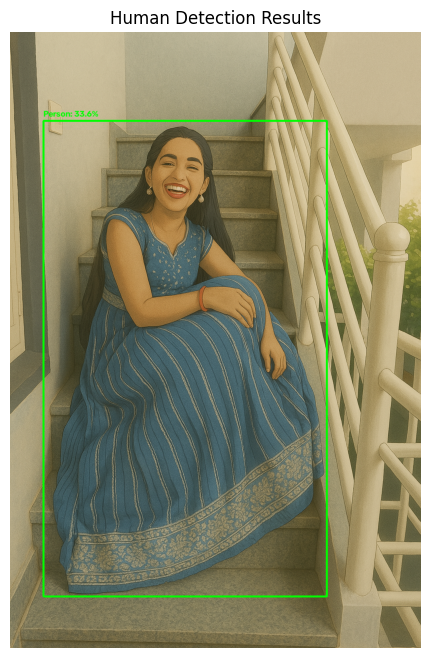

Total human detections: 1


In [12]:

output_img = img_rgb.copy()

boxes = np.asarray(
    results["detection_boxes"]
).reshape(-1, 4)

scores = np.asarray(
    results["detection_scores"]
).reshape(-1)

classes = np.asarray(
    results["detection_class_entities"]
).reshape(-1)

# Detect whole-person categories, not just faces
human_labels = {"person", "man", "woman", "people", "human face"}

threshold = 0.30
height, width = output_img.shape[:2]

# Keep only confident human-related predictions
human_indices = []

for i, raw_label in enumerate(classes):
    label = raw_label.decode("utf-8") if isinstance(
        raw_label, bytes
    ) else str(raw_label)

    if label.strip().lower() in human_labels:
        if scores[i] >= threshold:
            human_indices.append(i)

# Convert boxes to OpenCV format: x, y, width, height
pixel_boxes = []

for i in human_indices:
    ymin, xmin, ymax, xmax = boxes[i]

    pixel_boxes.append([
        int(xmin * width),
        int(ymin * height),
        int((xmax - xmin) * width),
        int((ymax - ymin) * height)
    ])

# Apply NMS only to human-related detections
selected = []

if human_indices:
    selected = cv2.dnn.NMSBoxes(
        pixel_boxes,
        [float(scores[i]) for i in human_indices],
        threshold,
        0.4
    )

detected_count = 0

if len(selected) > 0:
    for j in np.asarray(selected).reshape(-1):
        i = human_indices[j]

        ymin, xmin, ymax, xmax = boxes[i]

        x1 = max(0, min(int(xmin * width), width - 1))
        y1 = max(0, min(int(ymin * height), height - 1))
        x2 = max(0, min(int(xmax * width), width - 1))
        y2 = max(0, min(int(ymax * height), height - 1))

        raw_label = classes[i]
        label = raw_label.decode("utf-8") if isinstance(
            raw_label, bytes
        ) else str(raw_label)

        confidence = float(scores[i]) * 100

        cv2.rectangle(
            output_img, (x1, y1), (x2, y2),
            (0, 255, 0), 3
        )

        cv2.putText(
            output_img,
            f"{label}: {confidence:.1f}%",
            (x1, max(y1 - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (0, 255, 0), 2
        )

        print(f"{label}: {confidence:.1f}%")
        detected_count += 1

plt.figure(figsize=(10, 8))
plt.imshow(output_img)
plt.title("Human Detection Results")
plt.axis("off")
plt.show()

print("Total human detections:", detected_count)
